# 统计学习导论作业 2：离散选择与 Logistic 回归

**主题：** 二元 Logit / Probit / cloglog 对比，以及数字和鸢尾花多分类  
**姓名：** 咸蛋超人迪卡　**班级：** 统计　**学号：** 114514

## 一、范围

本作业先用二元诊断数据比较 Logit、Probit、互补双对数（cloglog）三种链接函数，再用手写数字和鸢尾花数据来体现 Logistic 回归的多分类能力。

Probit 与 cloglog 是二元响应模型的横向扩展；手写数字与鸢尾花部分对应课件中的多分类类别输出。各节都从训练数据估计类别概率，再根据评估目标生成预测类别。数字与鸢尾花提供多分类基准，大样本银行营销案例检验二元选择模型在类别不平衡和混合类型特征下的表现。

## 二、二元离散选择模型：乳腺癌诊断

目标设为 **恶性=1、良性=0**。使用 scikit-learn 自带的 Wisconsin 乳腺癌诊断数据，共 569 个样本、30 个图像测量特征。该数据来自威斯康星大学医院乳腺肿块细针穿刺图像（[数据说明](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset)）。为便于解释和降低共线性，只选六个 `mean` 特征：半径、纹理、平滑度、紧实度、凹陷程度、对称性。

模型令 $p=P(Y=1\mid x)$、$\eta=x^\top\beta$：Logit 使用 $\log\{p/(1-p)\}=\eta$；Probit 使用 $\Phi^{-1}(p)=\eta$；cloglog 使用 $\log[-\log(1-p)]=\eta$。三者将概率映射到实数轴，再以线性预测量拟合。Logit 与 Probit 的 S 形概率曲线接近；cloglog 不对称，允许两端概率变化速度不同。

### 2.1 载入数据并核对类别

原始 sklearn 标签为恶性 0、良性 1，这里反转编码，使所有模型的正类概率都表示恶性概率。

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, log_loss,
                             brier_score_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, average_precision_score,
                             precision_score, recall_score, precision_recall_curve)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
import statsmodels.api as sm

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=FutureWarning)

cancer = load_breast_cancer(as_frame=True)
binary_features = ["mean radius", "mean texture", "mean smoothness",
                   "mean compactness", "mean concavity", "mean symmetry"]
X_binary = cancer.data[binary_features].copy()
y_binary = (cancer.target == 0).astype(int).rename("恶性")
print("样本数：", len(X_binary))
print("恶性比例：", round(y_binary.mean(), 3))
display(pd.concat([X_binary.head(), y_binary.head()], axis=1))

样本数： 569
恶性比例： 0.373


,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean symmetry,恶性
0,17.99,10.38,0.11840,0.27760,0.3001,0.2419,1
1,20.57,17.77,0.08474,0.07864,0.0869,0.1812,1
2,19.69,21.25,0.10960,0.15990,0.1974,0.2069,1
3,11.42,20.38,0.14250,0.28390,0.2414,0.2597,1
4,20.29,14.34,0.10030,0.13280,0.1980,0.1809,1


### 2.2 分层划分与 Logistic 调参

测试集占 25%，按类别分层抽样。训练集上使用五折交叉验证搜索 `C`，评分采用 Log Loss。较小的 `C` 对应较强的 L2 正则化。标准化步骤放在 Pipeline 内，所以每折仅用该折训练部分估计均值和标准差。

In [2]:
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_binary, y_binary, test_size=0.25, random_state=42, stratify=y_binary
)
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
binary_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=5000)),
])
binary_search = GridSearchCV(
    binary_pipeline, {"model__C": np.logspace(-3, 3, 19)},
    scoring="neg_log_loss", cv=binary_cv, n_jobs=1,
    return_train_score=True,
)
binary_search.fit(Xb_train, yb_train)
print("最优 C：", binary_search.best_params_["model__C"])
print(f"五折交叉验证 Log Loss：{-binary_search.best_score_:.4f}")

最优 C： 4.6415888336127775
五折交叉验证 Log Loss：0.1563


### 2.3 拟合 Logit、Probit 与互补双对数

三种 statsmodels 模型使用相同特征和训练集标准化结果。它们通过极大似然估计；sklearn Logistic 则使用交叉验证选出的 L2 正则化强度。Logit 两种实现的差别可用于观察惩罚项对结果的影响。

In [3]:
# 只以训练集拟合标准化器，再用同一变换处理测试集。
binary_scaler = StandardScaler().fit(Xb_train)
Xbs_train = pd.DataFrame(binary_scaler.transform(Xb_train), columns=binary_features, index=Xb_train.index)
Xbs_test = pd.DataFrame(binary_scaler.transform(Xb_test), columns=binary_features, index=Xb_test.index)
Xbs_train_sm = sm.add_constant(Xbs_train, has_constant="add")
Xbs_test_sm = sm.add_constant(Xbs_test, has_constant="add")

binary_logit = sm.Logit(yb_train, Xbs_train_sm).fit(disp=False, maxiter=300)
binary_probit = sm.Probit(yb_train, Xbs_train_sm).fit(disp=False, maxiter=300)
binary_cloglog = sm.GLM(
    yb_train, Xbs_train_sm,
    family=sm.families.Binomial(link=sm.families.links.CLogLog()),
).fit(maxiter=300)

# 统一让每个模型输出“恶性”的概率，便于对同一测试集计算指标。
binary_probabilities = {
    "Logistic（L2 调参）": binary_search.best_estimator_.predict_proba(Xb_test)[:, 1],
    "Logit（无惩罚）": binary_logit.predict(Xbs_test_sm),
    "Probit": binary_probit.predict(Xbs_test_sm),
    "互补双对数 cloglog": binary_cloglog.predict(Xbs_test_sm),
}
binary_probabilities = {k: np.clip(np.asarray(v), 1e-8, 1 - 1e-8)
                        for k, v in binary_probabilities.items()}
print("收敛状态：Logit", binary_logit.mle_retvals["converged"],
      "| Probit", binary_probit.mle_retvals["converged"],
      "| cloglog", binary_cloglog.converged)

收敛状态：Logit True | Probit True | cloglog True


### 2.4 二元模型测试表现

ROC AUC 衡量排序能力；Log Loss 和 Brier 衡量概率质量；准确率使用统一的 0.5 阈值，仅作为补充。几种指标关注的目标不同，特别是准确率不反映预测概率离真实结果有多远。

In [4]:
binary_rows = []
for name, prob in binary_probabilities.items():
    predicted = (prob >= 0.5).astype(int)
    binary_rows.append({
        "模型": name,
        "ROC AUC ↑": roc_auc_score(yb_test, prob),
        "Log Loss ↓": log_loss(yb_test, prob),
        "Brier ↓": brier_score_loss(yb_test, prob),
        "准确率（阈值 0.5）": accuracy_score(yb_test, predicted),
    })
binary_results = pd.DataFrame(binary_rows).sort_values("Log Loss ↓").reset_index(drop=True)
display(binary_results.style.format({c: "{:.4f}" for c in binary_results.columns if c != "模型"}))

,模型,ROC AUC ↑,Log Loss ↓,Brier ↓,准确率（阈值 0.5）
0,Logistic（L2 调参）,0.9851,0.1458,0.0462,0.9301
1,Probit,0.9845,0.1469,0.0470,0.9441
2,互补双对数 cloglog,0.9847,0.1470,0.0476,0.9371
3,Logit（无惩罚）,0.9851,0.1482,0.0472,0.9371


### 2.5 二元模型调参和诊断图

Logistic `C` 曲线显示训练折和验证折损失；ROC 曲线展示不同阈值下真正率与假正率；混淆矩阵的行是真实标签、列是预测标签。恶性被判良性是假阴性，实际筛查中可能比误报代价更高，因此阈值应由业务代价确定。

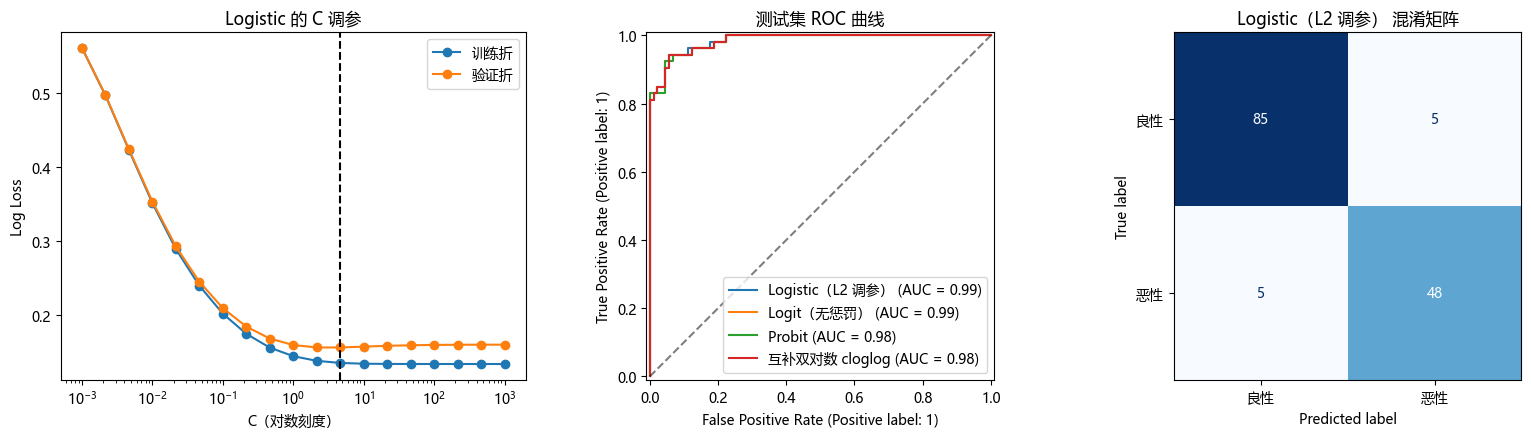

测试集 Log Loss 最低： Logistic（L2 调参）
三种 GLM 链接收敛： True True True


In [5]:
search_frame = pd.DataFrame(binary_search.cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].semilogx(search_frame["param_model__C"].astype(float),
                 -search_frame["mean_train_score"], marker="o", label="训练折")
axes[0].semilogx(search_frame["param_model__C"].astype(float),
                 -search_frame["mean_test_score"], marker="o", label="验证折")
axes[0].axvline(binary_search.best_params_["model__C"], color="black", linestyle="--")
axes[0].set(title="Logistic 的 C 调参", xlabel="C（对数刻度）", ylabel="Log Loss")
axes[0].legend()
for name, prob in binary_probabilities.items():
    RocCurveDisplay.from_predictions(yb_test, prob, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("测试集 ROC 曲线")
best_binary = binary_results.iloc[0]["模型"]
ConfusionMatrixDisplay.from_predictions(
    yb_test, (binary_probabilities[best_binary] >= 0.5).astype(int),
    display_labels=["良性", "恶性"], cmap="Blues", ax=axes[2], colorbar=False
)
axes[2].set_title(f"{best_binary} 混淆矩阵")
plt.tight_layout()
plt.show()
print("测试集 Log Loss 最低：", best_binary)
print("三种 GLM 链接收敛：", binary_logit.mle_retvals["converged"],
      binary_probit.mle_retvals["converged"], binary_cloglog.converged)

## 五、大样本二元选择：银行定期存款营销

### 5.1 研究问题与数据

为了检验 Logit 在真实业务型数据上的表现，使用 UCI Machine Learning Repository 的 **Bank Marketing `bank-full`** 数据。数据记录葡萄牙银行电话营销活动，共 **45,211 次客户联系、16 个预测变量**；响应变量 `y` 表示客户是否认购定期存款（yes/no）。来源：[UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)。

目标定义为 `认购=1、未认购=0`。响应率约 11.7%，类别明显不平衡，直接预测多数类就能获得较高准确率，因此本节以 Average Precision（PR-AUC）调参，并同时报告 ROC AUC、Log Loss、Brier、精确率、召回率和 F1。

预测时点设在电话联系开始之前，因此特征中排除 `duration`（通话持续时间）。`pdays=-1` 表示此前没有联系，建模时拆成“此前是否联系”和“此前联系后的天数”两个变量。模型估计认购响应倾向，系数表示控制其他输入后的关联方向。

### 5.2 数据检查与探索

先检查记录数、字段类型、响应比例和重复行，再比较月份与联系渠道的历史认购率。分组认购率用于描述样本中的业务差异，图中样本量同时显示以便区分大组与小组的估计稳定性。

记录数：45,211；预测变量数：16
总体认购率：11.70%
完全重复行： 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,subscribed
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0


,人数,比例
认购结果,,
no,39922,0.883
yes,5289,0.117


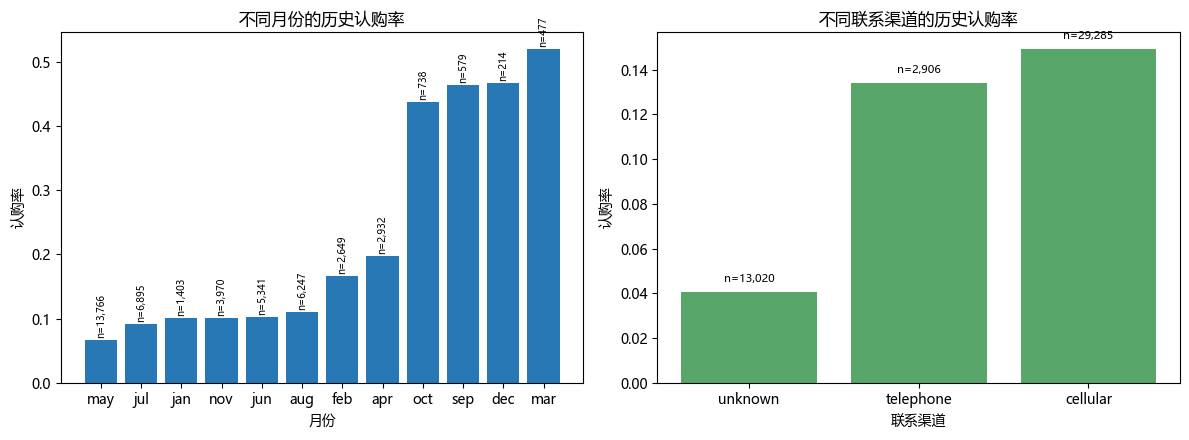

In [6]:
from pathlib import Path

# 文件与笔记本一起交付，按相对路径读取即可离线复现。
bank_path = Path("../data/bank-full.csv")
bank = pd.read_csv(bank_path, sep=";")
bank["subscribed"] = (bank["y"] == "yes").astype(int)
print(f"记录数：{len(bank):,}；预测变量数：{bank.shape[1] - 2}")
print(f"总体认购率：{bank['subscribed'].mean():.2%}")
print("完全重复行：", int(bank.duplicated().sum()))
display(bank.head())
display(bank["y"].value_counts().rename_axis("认购结果").to_frame("人数").assign(比例=lambda d: d["人数"] / len(bank)).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
month_rate = bank.groupby("month")["subscribed"].agg(["mean", "count"]).sort_values("mean")
axes[0].bar(month_rate.index, month_rate["mean"], color="#2878B5")
axes[0].set(title="不同月份的历史认购率", ylabel="认购率", xlabel="月份")
for i, row in enumerate(month_rate.itertuples()):
    axes[0].text(i, row.mean + 0.003, f"n={row.count:,}", ha="center", va="bottom", fontsize=7, rotation=90)

contact_rate = bank.groupby("contact")["subscribed"].agg(["mean", "count"]).sort_values("mean")
axes[1].bar(contact_rate.index, contact_rate["mean"], color="#58A66A")
axes[1].set(title="不同联系渠道的历史认购率", ylabel="认购率", xlabel="联系渠道")
for i, row in enumerate(contact_rate.itertuples()):
    axes[1].text(i, row.mean + 0.003, f"n={row.count:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

### 5.3 按预测时点建立训练、验证和测试集

采用分层的 **60% 训练 / 20% 验证 / 20% 测试** 划分。训练集内使用三折分层交叉验证搜索正则化强度，验证集选择分类阈值，测试集保留到最后。响应比例在各子集中保持一致。

完整特征集包含数值字段和类别字段。数值字段使用训练折标准化；类别字段使用 One-Hot 编码，未知类别在预测时被忽略。所有预处理都放在 Pipeline / ColumnTransformer 中，因此交叉验证每折都从本折训练样本重新估计变换。

In [7]:
target = bank["subscribed"]
X_bank = bank.drop(columns=["y", "subscribed", "duration", "pdays"]).copy()
X_bank["previously_contacted"] = (bank["pdays"] >= 0).astype(int)
X_bank["days_since_contact"] = bank["pdays"].where(bank["pdays"] >= 0, 0)
numeric_columns = X_bank.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_bank.select_dtypes(exclude=np.number).columns.tolist()

X_bank_train_val, X_bank_test, y_bank_train_val, y_bank_test = train_test_split(
    X_bank, target, test_size=0.20, random_state=42, stratify=target
)
X_bank_train, X_bank_val, y_bank_train, y_bank_val = train_test_split(
    X_bank_train_val, y_bank_train_val, test_size=0.25,
    random_state=42, stratify=y_bank_train_val
)
print(f"训练：{len(X_bank_train):,} | 验证：{len(X_bank_val):,} | 测试：{len(X_bank_test):,}")
print(f"训练集认购率：{y_bank_train.mean():.2%} | 验证集：{y_bank_val.mean():.2%} | 测试集：{y_bank_test.mean():.2%}")
print("数值字段：", numeric_columns)
print("类别字段：", categorical_columns)

bank_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
])
bank_pipeline = Pipeline([
    ("preprocess", bank_preprocessor),
    ("model", LogisticRegression(solver="liblinear", max_iter=2000)),
])
bank_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
bank_search = GridSearchCV(
    bank_pipeline,
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    scoring="average_precision", cv=bank_cv, n_jobs=1,
    return_train_score=True,
)
bank_search.fit(X_bank_train, y_bank_train)
print("CV 选出的 C：", bank_search.best_params_["model__C"])
print(f"CV Average Precision：{bank_search.best_score_:.4f}")

训练：27,126 | 验证：9,042 | 测试：9,043
训练集认购率：11.70% | 验证集：11.70% | 测试集：11.70%
数值字段： ['age', 'balance', 'day', 'campaign', 'previous', 'previously_contacted', 'days_since_contact']
类别字段： ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


CV 选出的 C： 0.1
CV Average Precision：0.3977


### 5.4 以验证集确定营销名单阈值

分类阈值决定营销名单的规模：提高阈值通常提高精确率并减少联系人数，同时降低召回率；降低阈值会找到更多潜在认购客户，也会增加无响应联系。阈值在验证集上按 **F1 最大化** 选择，F1 是精确率与召回率的调和平均。确定阈值后，将同一规则应用于测试集，得到样本外的运营指标。

同时给出 0.5 阈值结果。对低响应率问题，0.5 往往产生很小的正类名单；比较两个阈值可量化预测概率进入实际决策时的取舍。

验证集 F1 最优阈值：0.1857
验证集精确率：0.444；召回率：0.472；F1：0.458


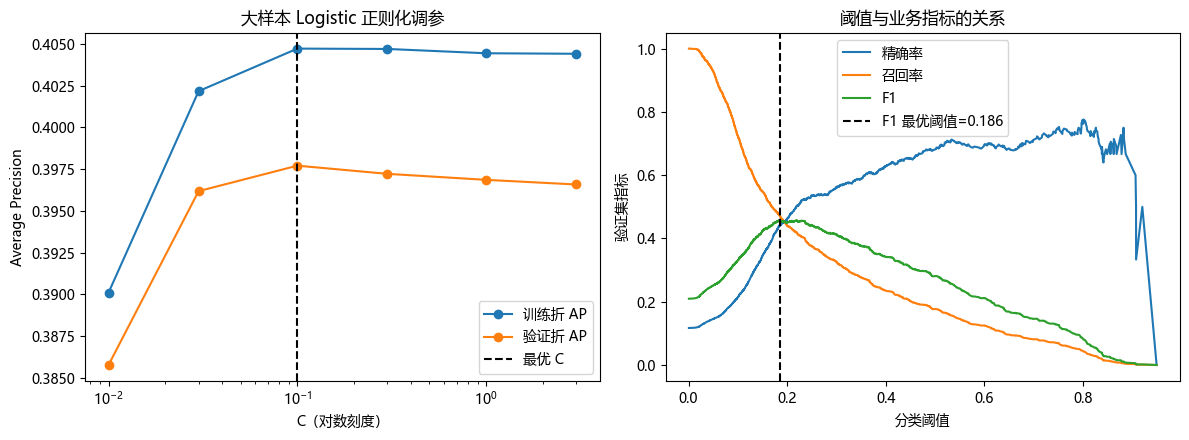

In [8]:
bank_model = bank_search.best_estimator_
bank_val_prob = bank_model.predict_proba(X_bank_val)[:, 1]
precision_curve, recall_curve, threshold_curve = precision_recall_curve(y_bank_val, bank_val_prob)
f1_curve = 2 * precision_curve[:-1] * recall_curve[:-1] / np.maximum(
    precision_curve[:-1] + recall_curve[:-1], 1e-12
)
best_threshold_index = int(np.argmax(f1_curve))
bank_threshold = float(threshold_curve[best_threshold_index])
print(f"验证集 F1 最优阈值：{bank_threshold:.4f}")
print(f"验证集精确率：{precision_curve[best_threshold_index]:.3f}；召回率：{recall_curve[best_threshold_index]:.3f}；F1：{f1_curve[best_threshold_index]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cv_table = pd.DataFrame(bank_search.cv_results_)
axes[0].semilogx(cv_table["param_model__C"].astype(float), cv_table["mean_train_score"], marker="o", label="训练折 AP")
axes[0].semilogx(cv_table["param_model__C"].astype(float), cv_table["mean_test_score"], marker="o", label="验证折 AP")
axes[0].axvline(bank_search.best_params_["model__C"], color="black", linestyle="--", label="最优 C")
axes[0].set(title="大样本 Logistic 正则化调参", xlabel="C（对数刻度）", ylabel="Average Precision")
axes[0].legend()
axes[1].plot(threshold_curve, precision_curve[:-1], label="精确率")
axes[1].plot(threshold_curve, recall_curve[:-1], label="召回率")
axes[1].plot(threshold_curve, f1_curve, label="F1")
axes[1].axvline(bank_threshold, color="black", linestyle="--", label=f"F1 最优阈值={bank_threshold:.3f}")
axes[1].set(xlabel="分类阈值", ylabel="验证集指标", title="阈值与业务指标的关系")
axes[1].legend()
plt.tight_layout()
plt.show()

### 5.5 测试集评价与多数类基准

多数类基准始终预测“未认购”，能显示类别不平衡下准确率的局限。Average Precision 以正类检出为重点，基线约等于响应率；ROC AUC 衡量整体排序；Log Loss 与 Brier 评价概率值。精确率回答联系名单中有多少人实际认购，召回率回答全部认购者中覆盖了多少。

测试集同时报告 0.5 阈值和验证集选出的阈值。阈值变动只改变概率到类别的映射，不会重新拟合模型。

,模型 / 阈值,阈值,Accuracy,ROC AUC,Average Precision,Log Loss,Brier,Precision,Recall,F1,营销名单比例
0,多数类概率基准,0.5000,0.8830,0.5000,0.1170,0.3609,0.1033,0.0000,0.0000,0.0000,0.0000
1,Logistic 固定阈值,0.5000,0.8930,0.7727,0.4113,0.2985,0.0853,0.6772,0.1626,0.2622,0.0281
2,Logistic 验证集 F1 阈值,0.1857,0.8648,0.7727,0.4113,0.2985,0.0853,0.4274,0.4594,0.4428,0.1257


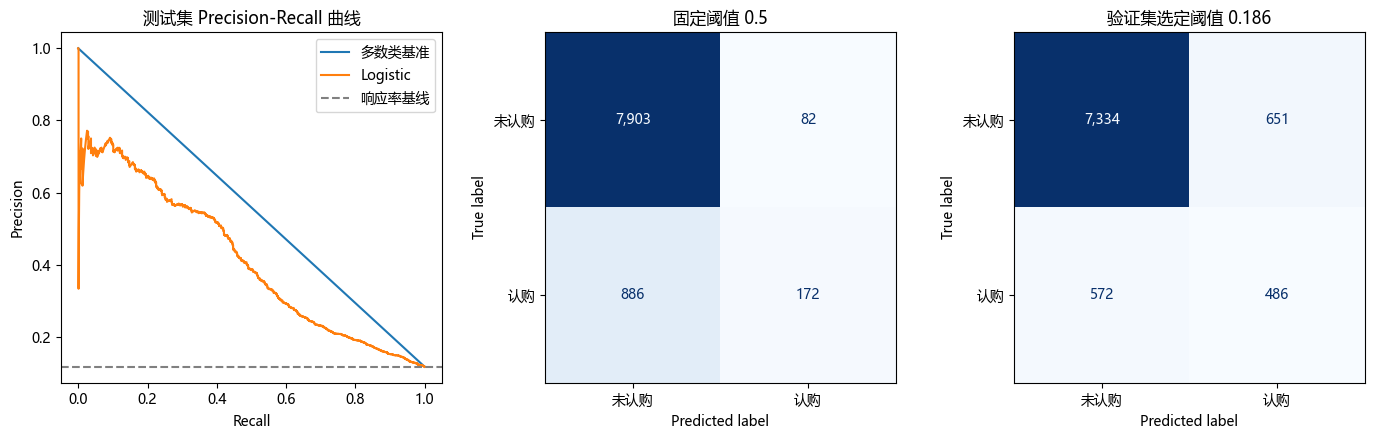

In [9]:
bank_test_prob = bank_model.predict_proba(X_bank_test)[:, 1]
bank_dummy = DummyClassifier(strategy="prior").fit(
    np.zeros((len(y_bank_train), 1)), y_bank_train
)
dummy_prob = np.full(len(y_bank_test), y_bank_train.mean())

def binary_metrics(name, y_true, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    return {
        "模型 / 阈值": name,
        "阈值": threshold,
        "Accuracy": accuracy_score(y_true, prediction),
        "ROC AUC": roc_auc_score(y_true, probability),
        "Average Precision": average_precision_score(y_true, probability),
        "Log Loss": log_loss(y_true, probability),
        "Brier": brier_score_loss(y_true, probability),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "营销名单比例": prediction.mean(),
    }

bank_test_results = pd.DataFrame([
    binary_metrics("多数类概率基准", y_bank_test.to_numpy(), dummy_prob, 0.5),
    binary_metrics("Logistic 固定阈值", y_bank_test.to_numpy(), bank_test_prob, 0.5),
    binary_metrics("Logistic 验证集 F1 阈值", y_bank_test.to_numpy(), bank_test_prob, bank_threshold),
])
display(bank_test_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for label, prob in [("多数类基准", dummy_prob), ("Logistic", bank_test_prob)]:
    precision, recall, _ = precision_recall_curve(y_bank_test, prob)
    axes[0].plot(recall, precision, label=label)
axes[0].axhline(y_bank_test.mean(), color="gray", linestyle="--", label="响应率基线")
axes[0].set(xlabel="Recall", ylabel="Precision", title="测试集 Precision-Recall 曲线")
axes[0].legend()

for ax, threshold, title in [
    (axes[1], 0.5, "固定阈值 0.5"),
    (axes[2], bank_threshold, f"验证集选定阈值 {bank_threshold:.3f}"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_bank_test, (bank_test_prob >= threshold).astype(int),
        display_labels=["未认购", "认购"], cmap="Blues", ax=ax, colorbar=False,
        values_format=",")
    ax.set_title(title)
plt.tight_layout()
plt.show()

### 5.6 模型系数与变量关联

对 One-Hot 编码后的数值特征和类别水平，系数表示标准化输入增加一个单位时对数优势的变化；指数化后是优势比。列出绝对值最大的系数可定位模型主要使用的特征。此前联系情况由二元变量表示，联系间隔天数只在曾联系的记录中取正值。

,模型特征,系数,优势比
49,categorical__poutcome_success,1.2933,3.6449
42,categorical__month_mar,0.9650,2.6247
39,categorical__month_jan,-0.9629,0.3818
34,categorical__contact_unknown,-0.9163,0.4000
47,categorical__poutcome_failure,-0.8240,0.4387
44,categorical__month_nov,-0.7707,0.4627
36,categorical__month_aug,-0.6812,0.5060
45,categorical__month_oct,0.6384,1.8935
46,categorical__month_sep,0.6228,1.8641
40,categorical__month_jul,-0.5926,0.5529


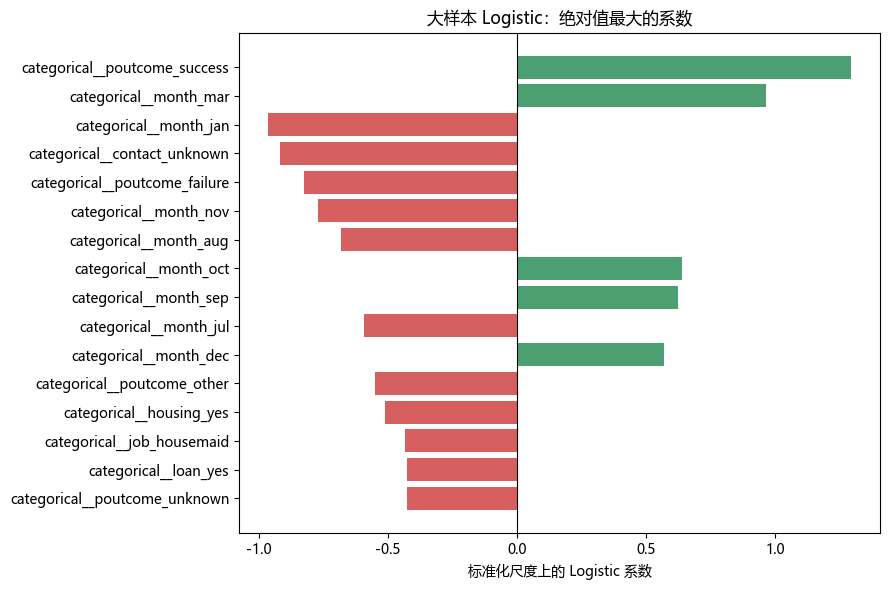

In [10]:
feature_names = bank_model.named_steps["preprocess"].get_feature_names_out()
coefficients = bank_model.named_steps["model"].coef_.ravel()
bank_coef = pd.DataFrame({"模型特征": feature_names, "系数": coefficients})
bank_coef["优势比"] = np.exp(np.clip(bank_coef["系数"], -20, 20))
bank_coef["绝对系数"] = bank_coef["系数"].abs()
display(bank_coef.sort_values("绝对系数", ascending=False).head(20).drop(columns="绝对系数").round(4))

top_coef = bank_coef.sort_values("绝对系数").tail(16)
fig, ax = plt.subplots(figsize=(9, 6))
colors = np.where(top_coef["系数"] > 0, "#4C9F70", "#D65F5F")
ax.barh(top_coef["模型特征"], top_coef["系数"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="大样本 Logistic：绝对值最大的系数", xlabel="标准化尺度上的 Logistic 系数")
plt.tight_layout()
plt.show()

### 5.7 同一数值特征下的 Logit、Probit 和 cloglog

链接函数的横向比较使用完全相同的数值变量：年龄、账户余额、联系日期、累计联系次数、距离上次联系天数和此前活动次数；分类变量留在上一节的全特征 Logistic 中。三种链接模型都用相同训练/验证/测试划分和训练集标准化结果，statsmodels 通过极大似然估计。这个子实验聚焦概率响应曲线的形状，指标可在同一测试样本中直接比较。

Logit、Probit、cloglog 均拟合于大样本，因此可以观察大样本二元选择模型的估计行为。`pdays=-1` 表示从未联系，本节将其转换为“是否曾联系”与“曾联系后的天数”，让模型分别识别联系历史和时间间隔。

In [11]:
link_numeric = ["age", "balance", "day", "campaign", "previous"]
X_link = bank[link_numeric].copy()
X_link["previously_contacted"] = (bank["pdays"] >= 0).astype(int)
X_link["days_since_contact"] = bank["pdays"].where(bank["pdays"] >= 0, 0)
Xl_trainval, Xl_test, yl_trainval, yl_test = train_test_split(
    X_link, target, test_size=0.20, random_state=42, stratify=target
)
Xl_train, Xl_val, yl_train, yl_val = train_test_split(
    Xl_trainval, yl_trainval, test_size=0.25,
    random_state=42, stratify=yl_trainval
)
link_scaler = StandardScaler().fit(Xl_train)
Xl_train_sm = sm.add_constant(link_scaler.transform(Xl_train), has_constant="add")
Xl_test_sm = sm.add_constant(link_scaler.transform(Xl_test), has_constant="add")
yl_train_np = yl_train.to_numpy()

link_models = {
    "Logit": sm.Logit(yl_train_np, Xl_train_sm).fit(disp=False, maxiter=200),
    "Probit": sm.Probit(yl_train_np, Xl_train_sm).fit(disp=False, maxiter=200),
    "cloglog": sm.GLM(
        yl_train_np, Xl_train_sm,
        family=sm.families.Binomial(link=sm.families.links.CLogLog()),
    ).fit(maxiter=200),
}
link_probabilities = {
    name: np.clip(np.asarray(model.predict(Xl_test_sm)), 1e-8, 1 - 1e-8)
    for name, model in link_models.items()
}
link_results = pd.DataFrame([{
    "链接函数": name,
    "ROC AUC": roc_auc_score(yl_test, prob),
    "Average Precision": average_precision_score(yl_test, prob),
    "Log Loss": log_loss(yl_test, prob),
    "Brier": brier_score_loss(yl_test, prob),
} for name, prob in link_probabilities.items()]).sort_values("Log Loss")
display(link_results.round(4))
def convergence_status(model):
    if hasattr(model, "converged"):
        return model.converged
    return model.mle_retvals.get("converged", True)

print("模型收敛状态：", {name: convergence_status(model)
                         for name, model in link_models.items()})

,链接函数,ROC AUC,Average Precision,Log Loss,Brier
2,cloglog,0.6588,0.2251,0.3412,0.0984
0,Logit,0.6593,0.2246,0.3412,0.0984
1,Probit,0.6600,0.2240,0.3414,0.0985


模型收敛状态： {'Logit': True, 'Probit': True, 'cloglog': True}


### 5.8 大样本分析结论

本次测试中，全特征 Logistic 的 Average Precision 为 0.411，高于响应率基线 0.117，ROC AUC 为 0.773。多数类基准准确率为 0.883，认购客户召回数为 0。验证集按 F1 选出的阈值为 0.186，应用到测试集后召回率为 0.459、精确率为 0.427，营销名单占测试样本的 12.6%。固定阈值 0.5 的召回率为 0.163，精确率为 0.677，名单占比为 2.8%。阈值降低扩大了名单并提高覆盖率，同时减少名单中的命中比例；这给出了联系成本与获客覆盖之间的量化权衡。

数值特征上的 Logit、Probit、cloglog 表格隔离了链接函数差异；全特征 Logistic 则利用职位、教育、联系渠道、月份等类别信息提高业务预测能力。系数排名反映模型的条件关联结构，阈值结果反映预测概率转成行动名单后的覆盖与命中表现。

## 三、多分类一：手写数字识别

`load_digits` 含 1,797 张 8×8 灰度手写数字图像，像素值为 0—16。将每张图展平成 64 维向量，标签为数字 0—9。LogisticRegression 在多类别任务中使用 softmax / multinomial 目标，为每个类别估计概率；模型预测概率最大的数字。

数据分为 75% 训练、25% 测试，训练集内五折交叉验证选择 L2 正则化强度。报告准确率和宏平均 F1：后者先计算每个数字类别的 F1 再平均，使每类表现同等重要。

In [12]:
digits = load_digits()
Xd = digits.data.astype(float)
yd = digits.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.25, random_state=42, stratify=yd
)
digits_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
digits_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(solver="lbfgs", max_iter=5000)),
])
digits_search = GridSearchCV(
    digits_pipe, {"model__C": np.logspace(-3, 2, 11)},
    scoring="f1_macro", cv=digits_cv, n_jobs=1, return_train_score=True,
)
digits_search.fit(Xd_train, yd_train)
digits_pred = digits_search.predict(Xd_test)
digits_prob = digits_search.predict_proba(Xd_test)
print("数字数据形状：", Xd.shape, "| 最优参数：", digits_search.best_params_)
print(f"测试准确率：{accuracy_score(yd_test, digits_pred):.4f}")
print(f"测试宏平均 F1：{f1_score(yd_test, digits_pred, average='macro'):.4f}")

数字数据形状： (1797, 64) | 最优参数： {'model__C': np.float64(3.1622776601683795)}
测试准确率：0.9733
测试宏平均 F1：0.9731


### 3.1 数字样本和混淆矩阵

混淆矩阵对角线表示识别正确的数字，非对角元素指出容易混淆的笔迹。下方样例逐张显示真实标签与模型预测。

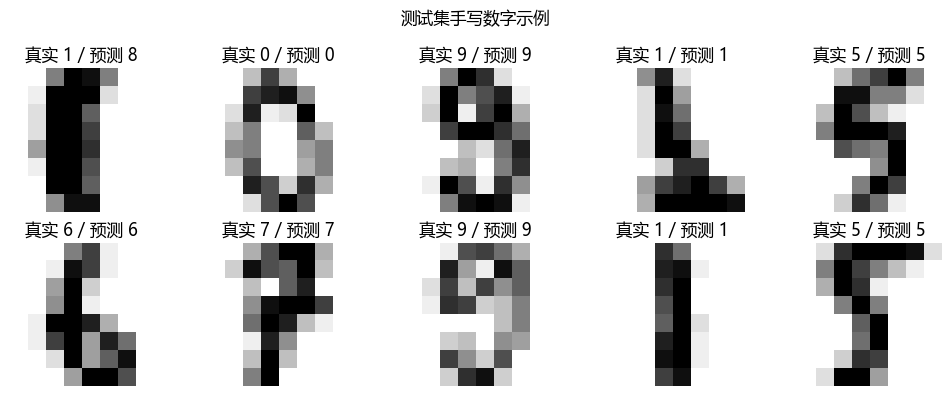

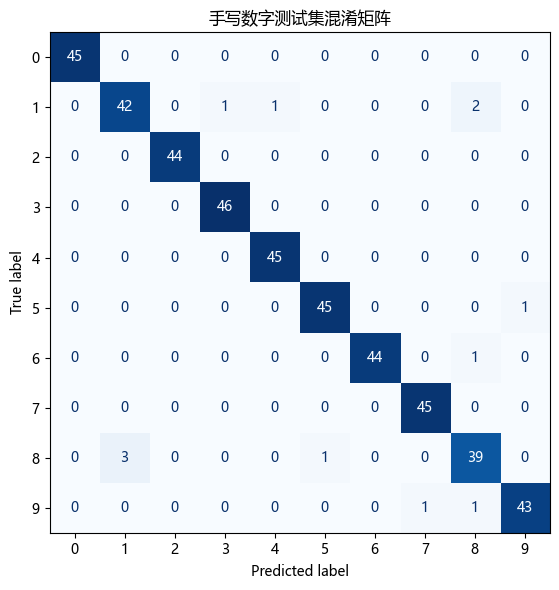

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.933     0.913     0.923        46
           2      1.000     1.000     1.000        44
           3      0.979     1.000     0.989        46
           4      0.978     1.000     0.989        45
           5      0.978     0.978     0.978        46
           6      1.000     0.978     0.989        45
           7      0.978     1.000     0.989        45
           8      0.907     0.907     0.907        43
           9      0.977     0.956     0.966        45

    accuracy                          0.973       450
   macro avg      0.973     0.973     0.973       450
weighted avg      0.973     0.973     0.973       450



In [13]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, index in zip(axes.ravel(), range(10)):
    ax.imshow(Xd_test[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"真实 {yd_test[index]} / 预测 {digits_pred[index]}")
    ax.axis("off")
fig.suptitle("测试集手写数字示例")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    yd_test, digits_pred, cmap="Blues", values_format="d", ax=ax, colorbar=False
)
ax.set_title("手写数字测试集混淆矩阵")
plt.tight_layout()
plt.show()
print(classification_report(yd_test, digits_pred, digits=3))

## 四、多分类二：鸢尾花识别

鸢尾花数据只有 150 个样本、4 个形态特征和 3 个物种类别，适合与数字任务对照：特征较少、样本较小、类别边界更易观察。为了比较多分类策略，分别拟合 sklearn 的 multinomial LogisticRegression 和 One-vs-Rest LogisticRegression。前者一次性估计归一化的多类概率；后者分别拟合“当前类别 vs 其他类别”的二元模型，再比较各模型分数。

使用分层 75/25 划分，并在训练集五折交叉验证中按宏平均 F1 调 `C`。小样本测试指标可能有较大波动，故结果只反映本次划分。

In [14]:
iris = load_iris(as_frame=True)
Xi = iris.data
yi = iris.target
iris_names = iris.target_names
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.25, random_state=42, stratify=yi
)
iris_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

iris_models = {
    "Multinomial Logistic": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(solver="lbfgs", max_iter=3000)),
    ]),
    "One-vs-Rest Logistic": Pipeline([
        ("scale", StandardScaler()),
        ("model", OneVsRestClassifier(LogisticRegression(solver="lbfgs", max_iter=3000))),
    ]),
}
iris_searches, iris_rows = {}, []
for name, estimator in iris_models.items():
    search = GridSearchCV(
        estimator, {"model__C": np.logspace(-3, 2, 11)} if name == "Multinomial Logistic"
        else {"model__estimator__C": np.logspace(-3, 2, 11)},
        scoring="f1_macro", cv=iris_cv, n_jobs=1, return_train_score=True,
    )
    search.fit(Xi_train, yi_train)
    iris_searches[name] = search
    prediction = search.predict(Xi_test)
    iris_rows.append({
        "模型": name, "CV 宏 F1": search.best_score_,
        "测试准确率": accuracy_score(yi_test, prediction),
        "测试宏 F1": f1_score(yi_test, prediction, average="macro"),
        "最优 C": next(iter(search.best_params_.values())),
    })
iris_results = pd.DataFrame(iris_rows).sort_values("CV 宏 F1", ascending=False)
display(iris_results.round(4))

,模型,CV 宏 F1,测试准确率,测试宏 F1,最优 C
0,Multinomial Logistic,0.9643,0.8947,0.8974,0.3162
1,One-vs-Rest Logistic,0.9643,0.8421,0.8469,3.1623


### 4.1 鸢尾花分类结果

观察每个类别的召回率，避免总体准确率掩盖某一物种识别较差。下图展示其中表现较好的策略在测试集的分类情况；特征散点图说明类别之间的可分性。

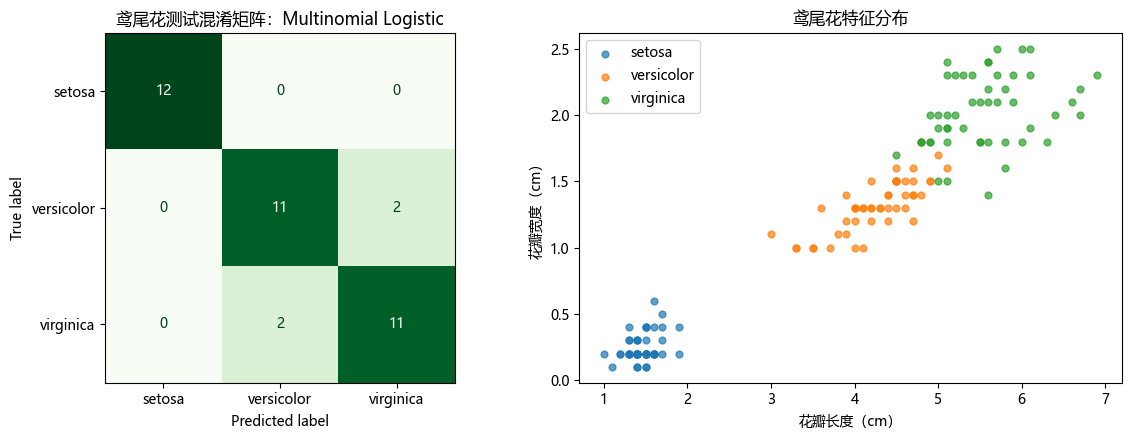

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        12
  versicolor      0.846     0.846     0.846        13
   virginica      0.846     0.846     0.846        13

    accuracy                          0.895        38
   macro avg      0.897     0.897     0.897        38
weighted avg      0.895     0.895     0.895        38



In [15]:
iris_best_name = iris_results.iloc[0]["模型"]
iris_best = iris_searches[iris_best_name].best_estimator_
iris_pred = iris_best.predict(Xi_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    yi_test, iris_pred, display_labels=iris_names, cmap="Greens",
    values_format="d", ax=axes[0], colorbar=False,
)
axes[0].set_title(f"鸢尾花测试混淆矩阵：{iris_best_name}")
for label, name in enumerate(iris_names):
    part = iris.data[iris.target == label]
    axes[1].scatter(part["petal length (cm)"], part["petal width (cm)"],
                    s=24, alpha=0.7, label=name)
axes[1].set(xlabel="花瓣长度（cm）", ylabel="花瓣宽度（cm）", title="鸢尾花特征分布")
axes[1].legend()
plt.tight_layout()
plt.show()
print(classification_report(yi_test, iris_pred, target_names=iris_names, digits=3))

## 五、总结与适用范围

二元部分说明不同链接函数如何把线性预测量转换成概率；多分类部分说明 LogisticRegression 能将同一思想扩展到多个类别。调参使用训练集交叉验证，阈值使用验证集确定，最终测试集用于独立报告。二元任务重视概率质量时以 Log Loss/Brier 为主，关注排序时看 AUC 或 Average Precision；多分类任务用准确率和宏平均 F1 并配合混淆矩阵查看各类别表现。

本次数字识别测试准确率为 0.973，宏平均 F1 为 0.973；鸢尾花测试中 Multinomial Logistic 准确率为 0.895，高于本次 One-vs-Rest 的 0.842。乳腺癌数据中 Logit、Probit 和 cloglog 的概率指标接近，说明在该特征集和划分下，三种链接函数给出了相近排序。银行营销大样本结果显示，类别不平衡时只报告 Accuracy 会掩盖正类召回；阈值调整能直接改变联系人群规模和命中/覆盖关系。手写数字和鸢尾花展示多分类 Logistic，乳腺癌数据展示二元链接函数，大样本营销数据展示不平衡响应预测。各节模型解释围绕预测关系和特征关联展开。